In [1]:
import pandas as pd, numpy as np, os
raw = "../data/raw"

tx_files = ["enugu_transactions.csv", "fct_transactions.csv", "kano_transactions.csv",
            "lagos_transactions.csv", "rivers_transactions.csv"]

frames = []
for f in tx_files:
    df = pd.read_csv(os.path.join(raw, f))
    df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]
    df["source_file"] = f
    print(f, df.shape)
    frames.append(df)

tx = pd.concat(frames, ignore_index=True)
print("Combined:", tx.shape)
print(tx.columns.tolist())
tx.head()

enugu_transactions.csv (350251, 8)
fct_transactions.csv (159652, 8)
kano_transactions.csv (458764, 8)
lagos_transactions.csv (755073, 8)
rivers_transactions.csv (420098, 8)
Combined: (2143838, 8)
['transactionid', 'transactionstartdatetime', 'transactionenddatetime', 'cardholderid', 'locationid', 'transactiontypeid', 'transactionamount', 'source_file']


,transactionid,transactionstartdatetime,transactionenddatetime,cardholderid,locationid,transactiontypeid,transactionamount,source_file
0,EN-2022-1000000001,1/1/2022 7:01,1/1/2022 7:04,EN-003-1067,EN-003,4,3000,enugu_transactions.csv
1,EN-2022-1000000002,1/1/2022 7:02,1/1/2022 7:06,EN-006-1040,EN-006,1,4000,enugu_transactions.csv
2,EN-2022-1000000003,1/1/2022 7:02,1/1/2022 7:07,EN-002-1080,EN-002,1,9000,enugu_transactions.csv
3,EN-2022-1000000004,1/1/2022 7:06,1/1/2022 7:12,EN-002-1024,EN-002,1,10000,enugu_transactions.csv
4,EN-2022-1000000005,1/1/2022 7:06,1/1/2022 7:09,EN-001-1095,EN-001,4,10000,enugu_transactions.csv


In [2]:
types = pd.read_csv(os.path.join(raw, "transaction_type lookup.csv"))
locs  = pd.read_csv(os.path.join(raw, "atm_location lookup.csv"))
display(types)
display(locs.head(10))

,TransactionTypeID,TransactionTypeName
0,1,Withdrawal
1,2,Deposit
2,3,Balance Inquiry
3,4,Transfer


,LocationID,Location Name,No of ATMs,City,State,Country
0,LA-001,Wisabi Bank HQ,7,Lagos,Lagos,Nigeria
1,LA-002,Victoria Island ATM,3,Lagos,Lagos,Nigeria
2,LA-003,Ikeja ATM,3,Lagos,Lagos,Nigeria
3,LA-004,Lekki ATM,3,Lagos,Lagos,Nigeria
4,LA-005,Surulere ATM,3,Lagos,Lagos,Nigeria
5,LA-006,Festac ATM,3,Lagos,Lagos,Nigeria
6,LA-007,Apapa ATM,3,Lagos,Lagos,Nigeria
7,LA-008,Ikorodu ATM,3,Lagos,Lagos,Nigeria
8,LA-009,Yaba ATM,3,Lagos,Lagos,Nigeria
9,LA-010,Maryland ATM,3,Lagos,Lagos,Nigeria


In [3]:
print(tx.isna().sum())
print(tx.dtypes)

transactionid               0
transactionstartdatetime    0
transactionenddatetime      0
cardholderid                0
locationid                  0
transactiontypeid           0
transactionamount           0
source_file                 0
dtype: int64
transactionid                 str
transactionstartdatetime      str
transactionenddatetime        str
cardholderid                  str
locationid                    str
transactiontypeid           int64
transactionamount           int64
source_file                   str
dtype: object


In [4]:
parts = tx["transactionstartdatetime"].str.split(" ").str[0].str.split("/", expand=True).astype(int)
print("first number max:", parts[0].max(), "| second number max:", parts[1].max())

first number max: 12 | second number max: 31


In [5]:
DAYFIRST = False   # set True if the first number's max was 31 in Cell 4

tx["datetime"] = pd.to_datetime(tx["transactionstartdatetime"], dayfirst=DAYFIRST)
tx["date"] = tx["datetime"].dt.normalize()
print("Date range:", tx["date"].min(), "to", tx["date"].max())

w = tx[tx["transactiontypeid"] == 1].copy()
print("Withdrawals:", w.shape)

Date range: 2022-01-01 00:00:00 to 2022-12-31 00:00:00
Withdrawals: (1189851, 10)


In [6]:
daily = (w.groupby(["locationid", "date"])
           .agg(total_amount=("transactionamount", "sum"),
                txn_count=("transactionamount", "count"))
           .reset_index())

# fill days with no withdrawals so every location has a continuous timeline
daily = (daily.set_index("date")
              .groupby("locationid")[["total_amount", "txn_count"]]
              .apply(lambda g: g.asfreq("D", fill_value=0))
              .reset_index())

# add the number of ATMs at each location
locs2 = locs.rename(columns={"LocationID": "locationid", "No of ATMs": "n_atms"})[["locationid", "n_atms"]]
daily = daily.merge(locs2, on="locationid", how="left")

print(daily.shape, "|", daily["locationid"].nunique(), "locations")
print(daily["n_atms"].isna().sum(), "rows with missing n_atms")
daily.head()

(18250, 5) | 50 locations
0 rows with missing n_atms


,locationid,date,total_amount,txn_count,n_atms
0,EN-001,2022-01-01,1415000,66,5
1,EN-001,2022-01-02,1328000,65,5
2,EN-001,2022-01-03,780000,49,5
3,EN-001,2022-01-04,1729000,74,5
4,EN-001,2022-01-05,1502000,73,5


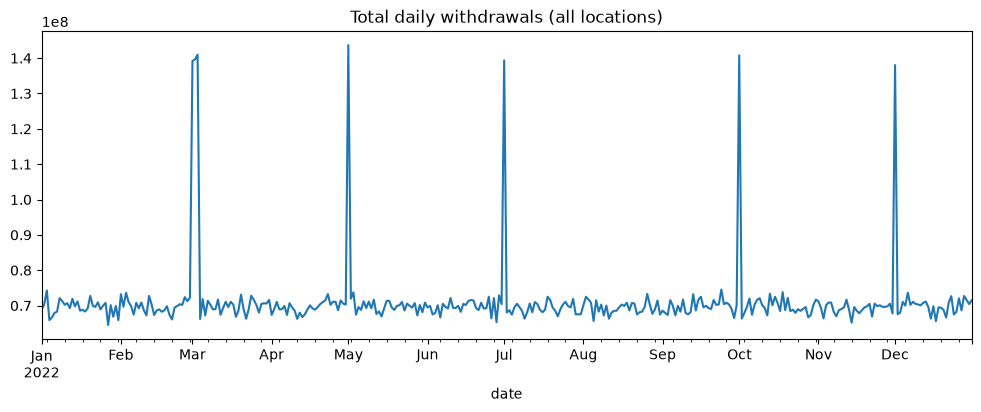

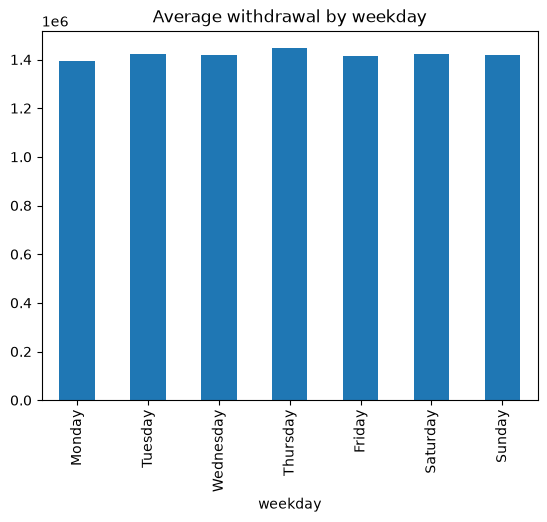

In [7]:
import matplotlib.pyplot as plt

daily.groupby("date")["total_amount"].sum().plot(figsize=(12, 4), title="Total daily withdrawals (all locations)")
plt.show()

daily.assign(weekday=daily["date"].dt.day_name()).groupby("weekday")["total_amount"].mean() \
     .reindex(["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]) \
     .plot(kind="bar", title="Average withdrawal by weekday")
plt.show()

In [8]:
daily = daily.sort_values(["locationid", "date"]).reset_index(drop=True)

d = daily["date"]
daily["dayofweek"] = d.dt.dayofweek
daily["day"] = d.dt.day
daily["is_weekend"] = (daily["dayofweek"] >= 5).astype(int)
daily["is_salary_week"] = ((daily["day"] <= 7) | (daily["day"] >= 28)).astype(int)

# history features: built only from past days, so there is no leakage
g = daily.groupby("locationid")
daily["lag_1"] = g["total_amount"].shift(1)
daily["lag_7"] = g["total_amount"].shift(7)
daily["roll_7"] = g["total_amount"].transform(lambda s: s.shift(1).rolling(7).mean())
daily["txn_lag_1"] = g["txn_count"].shift(1)

daily = daily.dropna().reset_index(drop=True)
daily = pd.get_dummies(daily, columns=["locationid"], prefix="loc", dtype=int)

feature_cols = [c for c in daily.columns if c not in ("date", "total_amount", "txn_count")]
print(len(feature_cols), "features")
print(daily.shape)

59 features
(17900, 62)


In [9]:
dates = np.sort(daily["date"].unique())
cut = dates[int(len(dates) * 0.8)]
print("Test starts on:", pd.Timestamp(cut).date())

train = daily[daily["date"] < cut]
test = daily[daily["date"] >= cut]

X_train, y_train = train[feature_cols], train["total_amount"]
X_test, y_test = test[feature_cols], test["total_amount"]
print(X_train.shape, X_test.shape)

Test starts on: 2022-10-21
(14300, 59) (3600, 59)


In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5, random_state=42),
}

def score(name, y_true, p):
    return {"Model": name,
            "MAE": mean_absolute_error(y_true, p),
            "RMSE": np.sqrt(mean_squared_error(y_true, p)),
            "R2": r2_score(y_true, p)}

rows, preds = [], {}
rows.append(score("Baseline (same as last week)", y_test, X_test["lag_7"]))

for name, m in models.items():
    m.fit(X_train, y_train)
    preds[name] = m.predict(X_test)
    rows.append(score(name, y_test, preds[name]))

results = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
results

,Model,MAE,RMSE,R2
0,XGBoost,225895.437500,310873.660872,0.473132
1,Random Forest,226978.521776,311217.708816,0.471965
2,Linear Regression,237757.742657,323863.248586,0.428182
3,Decision Tree,236947.741885,332770.356443,0.396297
4,Baseline (same as last week),311663.055556,424137.932557,0.019272


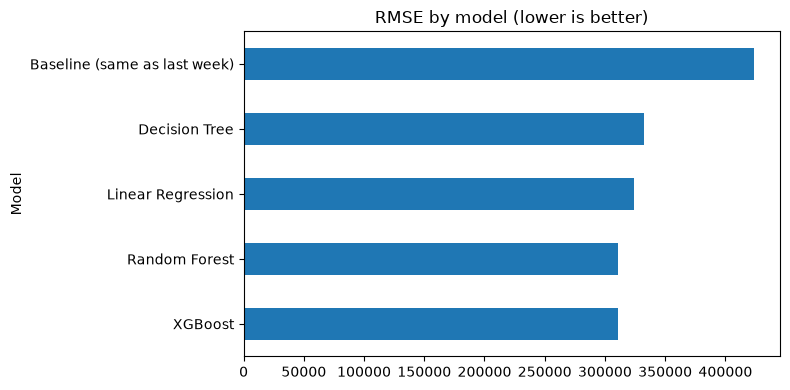

Best model: XGBoost


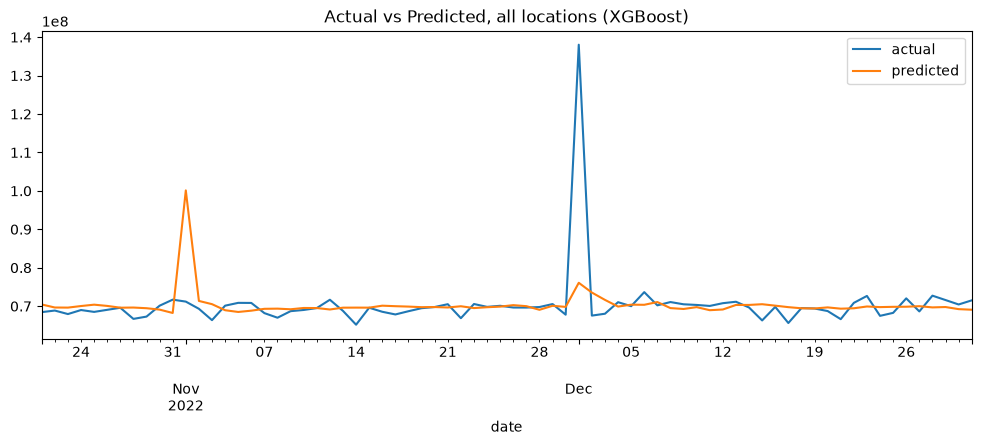

In [11]:
results.set_index("Model")["RMSE"].plot(kind="barh", title="RMSE by model (lower is better)", figsize=(8, 4))
plt.tight_layout()
plt.show()

best_name = results[results["Model"].isin(models.keys())].iloc[0]["Model"]
best_model = models[best_name]
print("Best model:", best_name)

cmp = test[["date"]].assign(actual=y_test.values, predicted=preds[best_name]).groupby("date").sum()
cmp.plot(figsize=(12, 4), title=f"Actual vs Predicted, all locations ({best_name})")
plt.show()

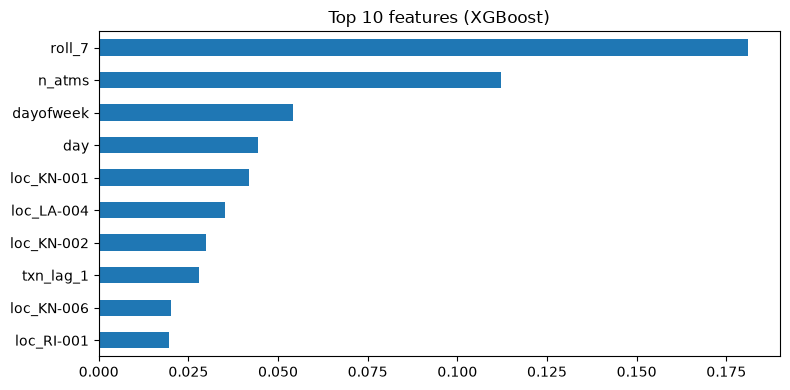

In [12]:
if hasattr(best_model, "feature_importances_"):
    imp = pd.Series(best_model.feature_importances_, index=feature_cols).sort_values(ascending=False).head(10)
    imp.plot(kind="barh", title=f"Top 10 features ({best_name})", figsize=(8, 4)).invert_yaxis()
    plt.tight_layout()
    plt.show()
else:
    print("Best model is Linear Regression, so there is no feature_importances_.")

In [13]:
import joblib
joblib.dump({"model": best_model, "feature_cols": feature_cols}, "../models/atm_model.pkl")
print("Saved")

Saved


In [14]:
print("Average daily withdrawal per location:", round(y_test.mean()))
print("MAE as % of average:", round(225895 / y_test.mean() * 100, 1), "%")

Average daily withdrawal per location: 1407622
MAE as % of average: 16.0 %


In [15]:
os.makedirs("../data/processed", exist_ok=True)

history = (w.groupby(["locationid", "date"])
             .agg(total_amount=("transactionamount", "sum"),
                  txn_count=("transactionamount", "count"))
             .reset_index())
history = (history.set_index("date")
                  .groupby("locationid")[["total_amount", "txn_count"]]
                  .apply(lambda g: g.asfreq("D", fill_value=0))
                  .reset_index())
history.to_csv("../data/processed/daily_history.csv", index=False)

loc_out = locs.rename(columns={"LocationID": "locationid",
                               "Location Name": "location_name",
                               "No of ATMs": "n_atms"})[["locationid", "location_name", "City", "n_atms"]]
loc_out.to_csv("../data/processed/locations.csv", index=False)

print(history.shape, loc_out.shape)

(18250, 4) (50, 4)
